# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional expression
notebook follows signatures directly.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the ends of
its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that pair: we score a
candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the mesenchymal /
neural-crest FOXC and PRRX factors** — along *this* trajectory (Gast/pSom-high origin → pSom-leaning
terminus) and let the data choose the most end-specific factor at each end, gated on detectable
expression. VIM is a mesenchymal marker, not a TF, and is excluded.

**Derived pair.** All eleven candidates survive the `min_cells` gene filter in this inDrop
compartment. Ranking by pseudotime correlation, **SNAI2** is the most root-end factor (rho ≈
−0.08, 5.1% of cells) and **TWIST2** the most terminus-end factor (rho ≈ +0.14, 1.7% of cells) —
both genuine EMT-inducing TFs at opposite ends of the axis. Sparsity is reported explicitly rather
than hidden behind a floor. The overlay is the reference **categorical** style: thresholded
expressers of each factor coloured on a grey manifold (not a continuous single-gene colormap).
Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 3920 | pseudotime range 0.0 -> 8.92


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Most negative correlation
marks the root end; most positive marks the terminus. The full panel is printed so the reader sees
each factor's detection. The two end-markers must be **different** factors so the overlay demarcates
the two ends rather than collapsing to one.

In [4]:
panel = ['SNAI1','SNAI2','SNAI3','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
missing = [g for g in panel if g not in adata.var_names]
print('candidate panel:', panel)
print('present (survived gene filter):', present)
print('undetectable (below min-cells filter):', missing)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0; rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), int(expr.sum()), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','n_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
FLOOR = 0.01
ok = df[df.frac_expr > FLOOR]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']              # most root-correlated
late_tf  = ok.sort_values('rho_vs_t', ascending=False).iloc[0]['TF']  # most terminus-correlated
print(f'\nderived pair: {early_tf} (early/root, rho<0) <-> {late_tf} (late/terminus, rho>0)')
print(f'({early_tf} in {float(df.set_index("TF").loc[early_tf,"frac_expr"])*100:.1f}% of cells; '
      f'{late_tf} in {float(df.set_index("TF").loc[late_tf,"frac_expr"])*100:.1f}% of cells; sparsity disclosed)')

candidate panel: ['SNAI1', 'SNAI2', 'SNAI3', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
present (survived gene filter): ['SNAI1', 'SNAI2', 'SNAI3', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
undetectable (below min-cells filter): []
    TF  frac_expr  n_expr  mean_early  mean_late  rho_vs_t            end
 SNAI2      0.051     201       0.035      0.015    -0.077    EARLY(root)
  ZEB2      0.039     152       0.030      0.019    -0.037    EARLY(root)
  ZEB1      0.015      58       0.011      0.004    -0.030    EARLY(root)
TWIST1      0.002       9       0.001      0.001     0.001 LATE(terminus)
 PRRX2      0.047     183       0.019      0.024     0.003 LATE(terminus)
 FOXC1      0.068     265       0.031      0.031     0.011 LATE(terminus)
 PRRX1      0.016      61       0.009      0.012     0.012 LATE(terminus)
 FOXC2      0.002       6       0.000      0.001     0.016 LATE(terminus)
 SNAI3      0.004      15       0.002      

### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Draw order set by abundance
(more widely-expressed factor first, sparser on top) so neither marker is occluded. Each factor is
thresholded at the upper quartile of expression among its expressing cells, so only the strongest
expressers show and the early (blue) / late (red) regions separate. This **categorical overlay of
thresholded expressers on a grey manifold** is the reference plotting style (not a continuous
single-gene colormap).

overlay thresholds (upper quartile among expressers): {'SNAI2': 0.731, 'TWIST2': 0.78} | cells shown: {'SNAI2': 50, 'TWIST2': 16}
SNAI2: 5.1% expressing; 50 shown (upper quartile), mean pseudotime of shown = 0.39 (all cells = 0.47)
TWIST2: 1.7% expressing; 16 shown (upper quartile), mean pseudotime of shown = 0.87 (all cells = 0.47)
shown-cell pseudotime separation (late TWIST2 - early SNAI2) = +0.48 (positive = correct ordering)
saved expression.pdf


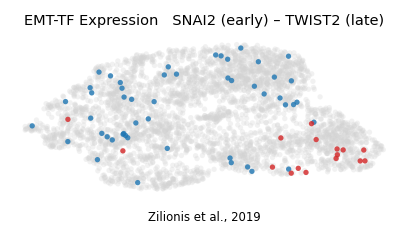

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) – {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean()
print(f'shown-cell pseudotime separation (late {late_tf} - early {early_tf}) = {sep:+.2f} (positive = correct ordering)')
print('saved expression.pdf')